In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("customer.csv")

In [4]:
df.head()

,CustomerID,Annual_Income,Spending_Score
0,1,26,17
1,2,29,31
2,3,13,15
3,4,25,22
4,5,24,19


In [5]:
df.shape

(30, 3)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      30 non-null     int64
 1   Annual_Income   30 non-null     int64
 2   Spending_Score  30 non-null     int64
dtypes: int64(3)
memory usage: 852.0 bytes


In [14]:
X = df.iloc[:,1:3]

In [15]:
print(X[:5])

   Annual_Income  Spending_Score
0             26              17
1             29              31
2             13              15
3             25              22
4             24              19


In [20]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

## to find value of k

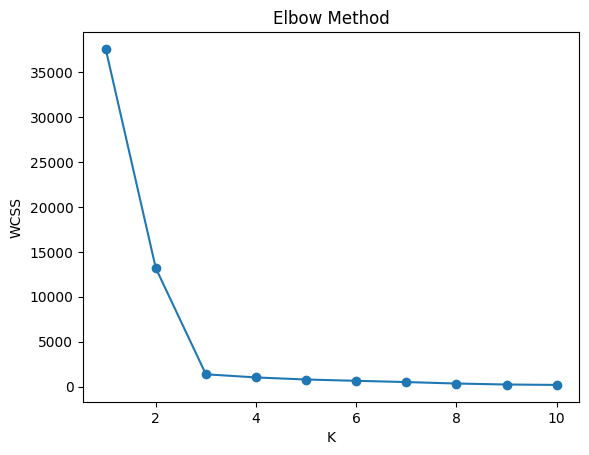

In [25]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1,11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('K')
plt.ylabel('WCSS')
plt.show()


## now for k=3

In [22]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)


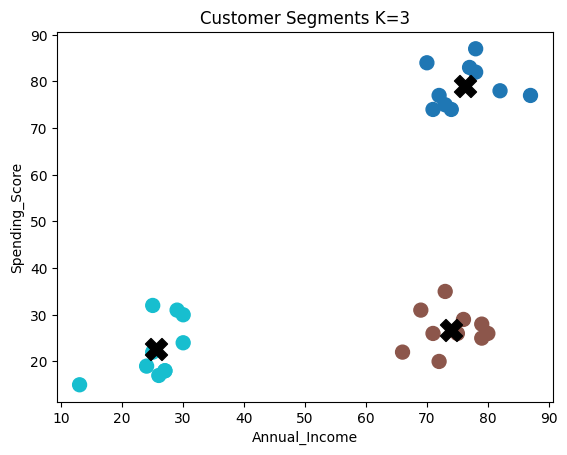

,CustomerID,Annual_Income,Spending_Score,Cluster
0,1,26,17,2
1,2,29,31,2
2,3,13,15,2
3,4,25,22,2
4,5,24,19,2


In [23]:
plt.scatter(df['Annual_Income'], df['Spending_Score'], c=df['Cluster'], cmap='tab10', s=100)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], s=250, c='black', marker='X')
plt.title('Customer Segments K=3')
plt.xlabel('Annual_Income')
plt.ylabel('Spending_Score')
plt.show()

df.head()

In [26]:
df.groupby('Cluster').mean()

,CustomerID,Annual_Income,Spending_Score
Cluster,,,
0,15.5,76.2,79.1
1,25.5,74.0,26.8
2,5.5,25.6,22.6
